# AIFS v10 — PJM on Kaggle, using BOTH GPUs (T4 x2)

**What this notebook does.** It is your v10 benchmark (same data pipeline, same 33 model implementations, same `STANDARD` budgets, same metrics) but the models are split between **two worker processes, one per GPU**, so the two 15 GB GPUs train at the same time. When the workers finish, the results are merged, then ensembles, leaderboards, Diebold–Mariano tests and the paper tables are produced exactly like in the Mac notebook.

**Kaggle settings (right-hand panel):**
1. *Accelerator* → **GPU T4 x2**.  *Internet* → **On** (needed for pip and the foundation-model weights).
2. *Add Data* → add the PJM file (search "Hourly Energy Consumption", or upload your own `PJMW_hourly.csv`).
3. **Continue an earlier run:** nothing to add. If this Kaggle session still has your old results in `/kaggle/working/aifs_results_STANDARD` (the folder every run writes to), they are **detected automatically**: finished models are skipped and only what is missing is run. Cell 3 prints a done / to-do table before the GPUs start. (If the session was reset, add the old notebook's output as input and it is found there instead.)
4. Best way to run: **Save Version → Save & Run All (Commit)**. It keeps running in the background (limit 12 h per session) and the outputs are saved.

If the 12 h limit is hit, nothing is lost: the notebook stops cleanly at `DEADLINE_HOURS`, then download the output folder, add it as a dataset, and run again — finished models are skipped automatically.

In [18]:
# import shutil

# shutil.make_archive(
#     '/kaggle/working/kaggle_output1',
#     'zip',
#     '/kaggle/working'
# )

In [19]:
# ============================================================
# CELL 1 — Environment check + install libraries  (no torch import here on purpose)
# ============================================================
import os, sys, subprocess, shutil, importlib.metadata as md_
INSTALL = True            # set False after the first run in the same session

def smi():
    try: return subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True).stdout
    except Exception: return ''
print(smi() or 'nvidia-smi: no GPU visible!  (Settings -> Accelerator -> GPU T4 x2)')
print('cpu cores:', os.cpu_count(), '| python', sys.version.split()[0])

def pip(*pk):
    r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *pk], capture_output=True, text=True)
    print(('ok    ' if r.returncode == 0 else 'FAILED'), ' '.join(pk), '' if r.returncode == 0 else '\n      ' + (r.stderr.strip().splitlines() or ['?'])[-1][:200])

if INSTALL:
    pip('optuna', 'holidays', 'seaborn', 'pyarrow')
    pip('prophet')
    pip('catboost')
    pip('chronos-forecasting')          # Chronos-Bolt / Chronos-2
    pip('tirex-ts')                     # TiRex
    pip('timesfm[torch]')               # TimesFM-2.5     (if one of these three fails, that model is simply skipped)

# check that torch still sees the GPUs (checked in a separate process so this kernel stays torch-free)
r = subprocess.run([sys.executable, '-c', "import torch; print('torch', torch.__version__, '| cuda', torch.version.cuda, '| gpus', torch.cuda.device_count(), [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])"], capture_output=True, text=True)
print(r.stdout.strip() or r.stderr.strip()[-300:])

GPU 0: Tesla T4 (UUID: GPU-9428eecc-5419-ab90-bc72-117efe4830c9)
GPU 1: Tesla T4 (UUID: GPU-e0f3666a-00ce-bf8c-54f4-1c57716889bb)

cpu cores: 4 | python 3.13.16
ok     optuna holidays seaborn pyarrow 
ok     prophet 
ok     catboost 
ok     chronos-forecasting 
ok     tirex-ts 
ok     timesfm[torch] 
torch 2.11.0+cu130 | cuda 13.0 | gpus 2 ['Tesla T4', 'Tesla T4']


In [20]:
# ============================================================
# CELL 2 — SETTINGS  (the only cell you normally edit)
# ============================================================
KCFG = dict(
    DATASET   = 'pjm',
    RUN_MODE  = 'STANDARD',      # keep STANDARD so PJM is comparable with ETTh1 / ETTh2 (same budgets)
    HORIZONS  = [1, 24],
    MODEL_SET = 'MAIN',          # 'MAIN' = 28 models (everything finished at 1 h in the first Kaggle run + Informer + 3 foundation models)
                                 # 'ALL' = every model incl. Autoformer / TimesNet / TFT / CVAE / Chronos-Bolt-base / TimesFM  |  or your own list
    N_WORKERS = 2,               # one worker per GPU; reduced automatically if only one GPU is visible
    PJM_FILE  = '/kaggle/input/datasets/akshdharodiya/pjmw-hourly/PJMW_hourly.csv',
    IMPORT_FROM = 'auto',        # 'auto' = use the old results already in /kaggle/working/aifs_results_STANDARD (or an input dataset) | a folder path | None = start from scratch
    DEADLINE_HOURS = 10.5,       # stop cleanly after this many hours (Kaggle sessions end at 12 h)
    MAX_RESTARTS   = 4,          # a worker that crashes is restarted (the crash-recovery logic skips the model that killed it)
    LOG_EVERY_MIN  = 5,
)

# MAIN = the 24 models your first single-GPU Kaggle run finished at H=1 (so they now get H=24 too) + Informer (interrupted) + Chronos-Bolt-small, TiRex, Chronos-2.
# Left out of MAIN (slow, and weak or unproven here): Autoformer, TimesNet, TFT, CVAE (diverged on PJM-LITE), Chronos-Bolt-base, TimesFM-2.5.
MAIN = ['Persistence', 'SeasonalNaive-24', 'SeasonalNaive-168', 'Ridge', 'Prophet', 'Prophet-Anchored', 'XGBoost', 'LightGBM', 'CatBoost', 'RandomForest', 'ExtraTrees',
        'MLP', 'LSTM', 'GRU', 'BiLSTM', 'CNN-LSTM', 'TCN', 'N-BEATS', 'N-HiTS', 'Transformer', 'PatchTST', 'iTransformer', 'DLinear', 'TSMixer',
        'Informer', 'Chronos-Bolt-small', 'TiRex', 'Chronos-2']
ALL = MAIN + ['Autoformer', 'TimesNet', 'TFT', 'CVAE', 'Chronos-Bolt-base', 'TimesFM-2.5']
MODELS = MAIN if KCFG['MODEL_SET'] == 'MAIN' else ALL if KCFG['MODEL_SET'] == 'ALL' else list(KCFG['MODEL_SET'])

# cost of one model at one horizon, in minutes on one T4 -> used only to split the work evenly between the two workers.
# Measured in your first Kaggle run (H=1) where available; the rest are estimates.
COST = {'Persistence': 0.1, 'SeasonalNaive-24': 0.1, 'SeasonalNaive-168': 0.1, 'Ridge': 0.1, 'Prophet': 10, 'Prophet-Anchored': 6, 'XGBoost': 2, 'LightGBM': 1, 'CatBoost': 1.5,
        'RandomForest': 34, 'ExtraTrees': 8, 'MLP': 9, 'LSTM': 44, 'GRU': 27, 'BiLSTM': 30, 'CNN-LSTM': 10, 'TCN': 18, 'N-BEATS': 19, 'N-HiTS': 14, 'Transformer': 30,
        'PatchTST': 15, 'iTransformer': 15, 'DLinear': 6, 'TSMixer': 20, 'Informer': 40, 'Autoformer': 90, 'TimesNet': 70, 'TFT': 90, 'CVAE': 40,
        'Chronos-Bolt-small': 5, 'Chronos-Bolt-base': 8, 'TimesFM-2.5': 40, 'TiRex': 25, 'Chronos-2': 30}
print(f"{len(MODELS)} models selected:", MODELS)

28 models selected: ['Persistence', 'SeasonalNaive-24', 'SeasonalNaive-168', 'Ridge', 'Prophet', 'Prophet-Anchored', 'XGBoost', 'LightGBM', 'CatBoost', 'RandomForest', 'ExtraTrees', 'MLP', 'LSTM', 'GRU', 'BiLSTM', 'CNN-LSTM', 'TCN', 'N-BEATS', 'N-HiTS', 'Transformer', 'PatchTST', 'iTransformer', 'DLinear', 'TSMixer', 'Informer', 'Chronos-Bolt-small', 'TiRex', 'Chronos-2']


In [21]:
# ============================================================
# CELL 3 — Write the pipeline files, import earlier results (optional), split models between the GPUs
# ============================================================
import os, glob, shutil, json, base64, zlib, subprocess, pathlib
WORK = pathlib.Path('/kaggle/working') if os.path.isdir('/kaggle/working') else pathlib.Path('kaggle_test_work')
WORK.mkdir(exist_ok=True); WORK = WORK.resolve()

_WORKER_B64 = """
...
"""
_MAIN_B64 = """
...
"""
unb = lambda s: zlib.decompress(base64.b64decode(''.join(s.split()))).decode('utf-8')
(WORK / 'aifs_worker.py').write_text(unb(_WORKER_B64))
MAIN_SETUP_SRC = unb(_MAIN_B64)
(WORK / 'aifs_main_setup.py').write_text(MAIN_SETUP_SRC)
print('written:', WORK / 'aifs_worker.py', f"({(WORK / 'aifs_worker.py').stat().st_size // 1024} KB)")

# ---- how many GPUs? (nvidia-smi: this kernel must not touch CUDA) ----
try: _smi = subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True).stdout
except Exception: _smi = ''
n_gpu = len([l for l in _smi.splitlines() if l.startswith('GPU')])
N_WORKERS = max(1, min(KCFG['N_WORKERS'], n_gpu if n_gpu else 1))
print(f'GPUs visible: {n_gpu} -> {N_WORKERS} worker(s)')

DSN = KCFG['DATASET']; RMODE = KCFG['RUN_MODE']
MAIN_DIR = WORK / f'aifs_results_{RMODE}'
W_DIRS = [WORK / f'w{i}' / f'aifs_results_{RMODE}' for i in range(N_WORKERS)]
for d in [MAIN_DIR] + W_DIRS: (d / 'preds').mkdir(parents=True, exist_ok=True); (d / 'tuning').mkdir(exist_ok=True)
safe_ = lambda s: ''.join(ch if ch.isalnum() or ch in '-_.' else '_' for ch in s)

# ---- continue an earlier run: the old results are in the SAME folder this notebook always writes to  (/kaggle/working/aifs_results_<MODE>) ----
import pandas as pd
def n_finished(folder):
    try:
        r = pd.read_csv(os.path.join(folder, 'results.csv'))
        return int(((r.dataset == DSN) & ((r.run_mode == RMODE) if 'run_mode' in r else True) & (~r.family.isin(['Ensemble']))).sum())
    except Exception: return 0
src = KCFG['IMPORT_FROM']
if src == 'auto':
    # 1) the notebook's own output folder (your earlier run in this same Kaggle notebook)   2) fallback: an earlier run added as Kaggle input
    cands = [str(MAIN_DIR)] + [os.path.dirname(p) for p in glob.glob('/kaggle/input/**/results.csv', recursive=True) if os.path.isdir(os.path.join(os.path.dirname(p), 'preds'))]
    scored = [(n_finished(c), c) for c in cands]
    for n, c in scored: print(f'  looked in {c}  ->  {n} finished {DSN} runs')
    src = max(scored)[1] if max(scored)[0] > 0 else None
if src and os.path.exists(os.path.join(src, 'results.csv')):
    R0 = pd.read_csv(os.path.join(src, 'results.csv'))
    print(f'using earlier results from {src}: {len(R0)} rows | datasets: {sorted(R0.dataset.unique())}')
    if os.path.abspath(src) != os.path.abspath(MAIN_DIR):                              # (only needed when the old run came from /kaggle/input)
        shutil.copy(os.path.join(src, 'results.csv'), MAIN_DIR / 'results.csv')
        for f in glob.glob(os.path.join(src, 'preds', '*.npz')): shutil.copy(f, MAIN_DIR / 'preds')
        for f in glob.glob(os.path.join(src, 'tuning', '*')):
            if os.path.isfile(f): shutil.copy(f, MAIN_DIR / 'tuning')
    mine = R0[(R0.dataset == DSN) & (R0.run_mode == RMODE)] if 'run_mode' in R0 else R0[R0.dataset == DSN]
    mine = mine[~mine.family.isin(['Ensemble'])]                                      # ensembles are rebuilt at the end from all models
    for d in W_DIRS:                                                                  # each GPU worker gets a copy of the finished models so it skips them
        mine.to_csv(d / 'results.csv', index=False)
        for k in mine.key:
            f = os.path.join(src, 'preds', safe_(k) + '.npz')
            if os.path.exists(f): shutil.copy(f, d / 'preds')
    done = {k for k in mine.key if os.path.exists(os.path.join(src, 'preds', safe_(k) + '.npz'))}
else:
    print('no earlier results found (starting from scratch)'); done = set()

# ---- what is done / what is still to do ----
print('\n   model                H=' + '   H='.join(map(str, KCFG['HORIZONS'])))
for m in MODELS:
    print(f'   {m:<20}' + '  '.join(('done ' if f"{DSN}|A|H{H}|{m}" in done else 'TO DO') for H in KCFG['HORIZONS']))
print()

# ---- split the models between the workers (greedy: biggest job to the least-loaded worker) ----
todo = [(m, H) for m in MODELS for H in KCFG['HORIZONS'] if f"{DSN}|A|H{H}|{m}" not in done]
cost_of = lambda m: COST.get(m, 30)
load = [0.0] * N_WORKERS; share = [[] for _ in range(N_WORKERS)]
for m in sorted({m for m, _ in todo}, key=lambda m: -sum(cost_of(m) for mm, _ in todo if mm == m)):
    w = min(range(N_WORKERS), key=lambda i: load[i]); share[w].append(m); load[w] += sum(cost_of(m) for mm, _ in todo if mm == m)
order = {m: i for i, m in enumerate(ALL)}
share = [sorted(s, key=lambda m: order.get(m, 99)) for s in share]
print(f'{len(todo)} model/horizon runs still to do ({len(done)} already finished)')
for i, s in enumerate(share): print(f'  worker {i} (GPU {i}) ~{load[i]:.0f} min-estimate: {s}')

written: /kaggle/working/aifs_worker.py (106 KB)
GPUs visible: 2 -> 2 worker(s)
  looked in /kaggle/working/aifs_results_STANDARD  ->  34 finished pjm runs
using earlier results from /kaggle/working/aifs_results_STANDARD: 38 rows | datasets: ['pjm']

   model                H=1   H=24
   Persistence         done   TO DO
   SeasonalNaive-24    done   TO DO
   SeasonalNaive-168   done   TO DO
   Ridge               done   TO DO
   Prophet             done   TO DO
   Prophet-Anchored    done   done 
   XGBoost             done   TO DO
   LightGBM            done   TO DO
   CatBoost            done   TO DO
   RandomForest        done   done 
   ExtraTrees          done   TO DO
   MLP                 done   done 
   LSTM                done   TO DO
   GRU                 done   TO DO
   BiLSTM              done   TO DO
   CNN-LSTM            done   TO DO
   TCN                 done   TO DO
   N-BEATS             done   done 
   N-HiTS              done   done 
   Transformer         done   

In [22]:
# ============================================================
# CELL 4 — RUN: one worker process per GPU.  Safe to interrupt and re-run (finished models are skipped).
# ============================================================
import subprocess, time, sys, os, re
T0 = time.time(); DEADLINE = T0 + KCFG['DEADLINE_HOURS'] * 3600
def launch(i):
    env = os.environ.copy()
    env.update(CUDA_VISIBLE_DEVICES=str(i) if n_gpu else '', AIFS_DATASET=DSN, AIFS_RUN_MODE=RMODE, AIFS_OUT_DIR=str(W_DIRS[i].parent / 'aifs_results'),
               AIFS_HORIZONS=','.join(map(str, KCFG['HORIZONS'])), AIFS_MODELS=','.join(share[i]), AIFS_PJM_FILE=KCFG['PJM_FILE'],
               OMP_NUM_THREADS=str(max(1, (os.cpu_count() or 4) // N_WORKERS)), PYTHONUNBUFFERED='1')
    log = open(WORK / f'worker{i}.log', 'a')
    return subprocess.Popen([sys.executable, '-u', str(WORK / 'aifs_worker.py')], env=env, stdout=log, stderr=subprocess.STDOUT, cwd=str(WORK)), log

def interesting(path, n=4):
    try:
        lines = open(path, errors='ignore').read().splitlines()
    except Exception: return []
    keep = [l for l in lines if re.search(r'✓|✗|SKIPPED|WORKER DONE|Traceback|Error|^# dataset', l)]
    return keep[-n:]

procs = {i: launch(i) for i in range(N_WORKERS) if share[i]}; restarts = {i: 0 for i in procs}; finished = set()
last_print = 0
try:
    while len(finished) < len(procs):
        time.sleep(20)
        for i, (p, lg) in list(procs.items()):
            if i in finished or p.poll() is None: continue
            if p.returncode == 0: finished.add(i); print(f'[{(time.time()-T0)/60:6.1f} min] worker {i} finished.')
            elif restarts[i] < KCFG['MAX_RESTARTS']:
                restarts[i] += 1; print(f'[{(time.time()-T0)/60:6.1f} min] worker {i} exited with code {p.returncode} -> restart {restarts[i]}/{KCFG["MAX_RESTARTS"]} (crash recovery skips the model that died)')
                lg.close(); procs[i] = launch(i)
            else: finished.add(i); print(f'worker {i} keeps failing -> giving up; see {WORK}/worker{i}.log')
        if time.time() - last_print > KCFG['LOG_EVERY_MIN'] * 60:
            last_print = time.time(); print(f'\n--- {(time.time()-T0)/3600:.2f} h elapsed ---')
            for i in procs: print(f'worker {i}:', *interesting(WORK / f'worker{i}.log', 3), sep='\n   ')
        if time.time() > DEADLINE:
            print(f'\nDEADLINE of {KCFG["DEADLINE_HOURS"]} h reached -> stopping the workers cleanly. Re-run from Cell 3 in a new session to finish the rest.'); break
except KeyboardInterrupt:
    print('interrupted -> stopping workers (finished models are saved)')
finally:
    for i, (p, lg) in procs.items():
        if p.poll() is None:
            p.terminate()
            try: p.wait(timeout=60)
            except Exception: p.kill()
        lg.close()
print(f'\nAll workers stopped after {(time.time()-T0)/60:.1f} min.')
for i in procs: print(f'worker {i}:', *interesting(WORK / f'worker{i}.log', 6), sep='\n   ')


--- 0.01 h elapsed ---
worker 0:
      ✓ SeasonalNaive-168    H=24  RMSE=779.7457  MAE=584.7712  NRMSE=14.05%  MASE=1.654  (val RMSE 794.0522)
      ✓ Ridge                H=24  RMSE=325.9882  MAE=239.3141  NRMSE=5.88%  MASE=0.677  (val RMSE 355.9666)
      ✓ Prophet              H=24  RMSE=816.4979  MAE=684.7658  NRMSE=14.72%  MASE=1.937  (val RMSE 726.2105)
worker 1:
   # dataset=pjm  setting=A  horizon=1h  mode=STANDARD
   Traceback (most recent call last):
   # dataset=pjm  setting=A  horizon=1h  mode=STANDARD

--- 0.09 h elapsed ---
worker 0:
      ✓ SeasonalNaive-24     H=24  RMSE=490.6370  MAE=368.5072  NRMSE=8.84%  MASE=1.042  (val RMSE 555.0696)
      ✓ SeasonalNaive-168    H=24  RMSE=779.7457  MAE=584.7712  NRMSE=14.05%  MASE=1.654  (val RMSE 794.0522)
      ✓ Ridge                H=24  RMSE=325.9882  MAE=239.3141  NRMSE=5.88%  MASE=0.677  (val RMSE 355.9666)
worker 1:
   # dataset=pjm  setting=A  horizon=1h  mode=STANDARD
      - Chronos-2            SKIPPED (kernel crashed

In [23]:
# ============================================================
# CELL 5 — MERGE the worker outputs into one results folder (then ensembles / tables run on it)
# ============================================================
import pandas as pd, shutil, glob
parts = [pd.read_csv(MAIN_DIR / 'results.csv')] if (MAIN_DIR / 'results.csv').exists() else []
for d in W_DIRS:
    if (d / 'results.csv').exists(): parts.append(pd.read_csv(d / 'results.csv'))
    for sub in ['preds', 'tuning']:
        for f in glob.glob(str(d / sub / '*')):
            if os.path.isfile(f): shutil.copy(f, MAIN_DIR / sub)
ALLR = pd.concat(parts, ignore_index=True).drop_duplicates('key', keep='last')
ALLR.to_csv(MAIN_DIR / 'results.csv', index=False)
mine = ALLR[(ALLR.dataset == DSN)]
print(f'merged results.csv: {len(ALLR)} rows ({len(mine)} for {DSN}). Models finished per horizon:')
print(mine.groupby('horizon').model.apply(lambda s: len(s)).to_string())
missing = [(m, H) for m in MODELS for H in KCFG['HORIZONS'] if f"{DSN}|A|H{H}|{m}" not in set(mine.key)]
print('still missing:', missing if missing else 'nothing — all selected models are done')
# sanity filter: a model whose error is absurd (diverged) is listed here and excluded from ensembles / tables below
bad = mine[(mine.RMSE > 20 * mine.groupby('horizon').RMSE.transform('median')) | ~mine.RMSE.apply(lambda x: x == x and abs(x) < 1e30)]
if len(bad): print('\nDIVERGED (excluded):', list(zip(bad.model, bad.horizon, bad.RMSE.round(1))))
ALLR[~ALLR.key.isin(bad.key)].to_csv(MAIN_DIR / 'results.csv', index=False)

merged results.csv: 57 rows (57 for pjm). Models finished per horizon:
horizon
1     28
24    29
still missing: [('Informer', 1), ('Informer', 24), ('Chronos-2', 1)]


Not macOS - no OpenMP guard needed.
RUN_MODE = STANDARD  |  dataset = pjm  |  horizons = [1, 24]  |  settings = ['A']
torch 2.11.0+cu130 | device = cpu | outputs -> /kaggle/working/aifs_results_STANDARD
libraries: {'xgboost': True, 'lightgbm': True, 'catboost': True, 'prophet': True, 'holidays': True}
Loaded 'pjm' in 0.3s | hourly shape (143232, 1) | 2002-04-01 01:00:00 → 2018-08-03 00:00:00
Missing target hours: 30 (0.02%)


,y
Datetime,
2002-04-01 01:00:00,4374.0
2002-04-01 02:00:00,4306.0
2002-04-01 03:00:00,4322.0


Hours used: 143232 | train 100262 | val 14323 | test 28647
Test period: 2015-04-27 10:00:00 → 2018-08-03 00:00:00 | mean test load = 5547.818
Past channels: 1 target + 0 covariates + 8 calendar = 9 | known-future channels in Setting A: 8 (0 covariates known in advance)
Metrics + result store ready. Existing results loaded: 57
Baselines + ML runners defined.
Architecture self-test passed for 13 networks (H=1 and H=24).
Extended architecture self-test passed: TSMixer, Informer, Autoformer, TimesNet, TFT (H=1 and H=24).
Neural training engine ready (device = cpu; auto device choice = True).
Foundation-model wrappers defined (Chronos-Bolt x2, TimesFM-2.5, TiRex, Chronos-2).
34 models active: ['Persistence', 'SeasonalNaive-24', 'SeasonalNaive-168', 'Ridge', 'Prophet', 'Prophet-Anchored', 'XGBoost', 'LightGBM', 'CatBoost', 'RandomForest', 'ExtraTrees', 'MLP', 'LSTM', 'GRU', 'BiLSTM', 'CNN-LSTM', 'TCN', 'N-BEATS', 'N-HiTS', 'Transformer', 'PatchTST', 'iTransformer', 'DLinear', 'TSMixer', 'Inf

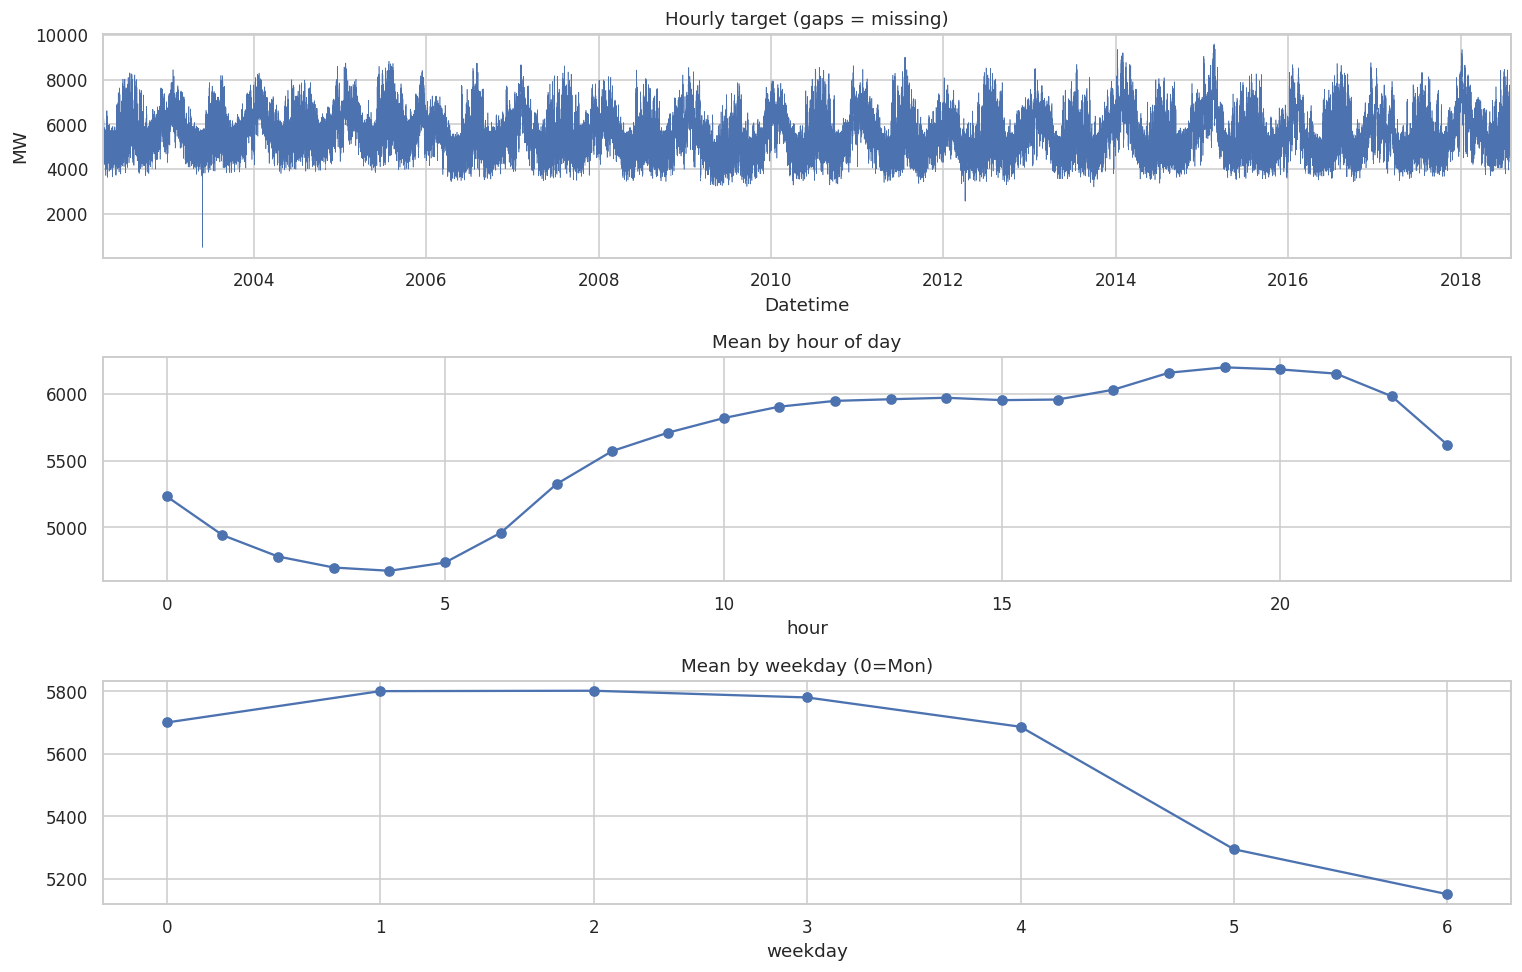

In [24]:
# ============================================================
# CELL 6 — Load data + models in THIS kernel on the CPU only (the GPUs belong to the workers), data summary + EDA
# ============================================================
import os
os.environ['CUDA_VISIBLE_DEVICES'] = ''            # this kernel only does ensembles / tables: no GPU needed
os.environ.update(AIFS_DATASET=DSN, AIFS_RUN_MODE=RMODE, AIFS_OUT_DIR=str(WORK / 'aifs_results'), AIFS_HORIZONS=','.join(map(str, KCFG['HORIZONS'])),
                  AIFS_PJM_FILE=KCFG['PJM_FILE'])
os.environ.pop('AIFS_MODELS', None)
exec(compile(MAIN_SETUP_SRC, 'aifs_main_setup.py', 'exec'), globals())

In [25]:
# ============================================================
# CELL 14 — Ensembles (top-3 mean, top-5 inverse-MSE) — weights chosen on VALIDATION only
# ============================================================
def load_pred(key): z = np.load(pred_path(key)); return z['val'], z['test']

def build_ensembles(setting, H):
    global RESULTS
    b = get_bundle(setting)
    sub = RESULTS[(RESULTS.dataset == DS_NAME) & (RESULTS.setting == setting) & (RESULTS.horizon == H) &
                  (~RESULTS.family.isin(['Ensemble', 'Baseline']))].sort_values('val_RMSE')
    if len(sub) < 3: print(f"   (H={H}) need ≥3 non-baseline models for ensembles — skipped"); return
    ov = get_origins(b, 'val', 1, H); yv, mv = targets(b, ov, H)
    for tag, k, weighted in [('Ens-Top3-Mean', 3, False), ('Ens-Top5-InvMSE', min(5, len(sub)), True)]:
        top = sub.head(k); pv = [load_pred(x)[0] for x in top.key]; pt = [load_pred(x)[1] for x in top.key]
        if weighted:
            w = np.array([1.0 / np.mean(((p - yv)[mv])**2) for p in pv]); w /= w.sum()
        else: w = np.ones(k) / k
        out = dict(pred_val=np.tensordot(w, pv, 1), pred_test_seeds=[np.tensordot(w, pt, 1)], train_time=np.nan, infer_ms=np.nan,
                   n_params=np.nan, best_params=dict(members=list(top.model), weights=[round(float(x), 3) for x in w]))
        finalize(tag, 'Ensemble', b, H, make_key(setting, H, tag), out)

for setting in CFG['SETTINGS']:
    for H in CFG['HORIZONS']:
        build_ensembles(setting, H)

   ✓ Ens-Top3-Mean        H=1   RMSE=53.6517  MAE=41.1672  NRMSE=0.97%  MASE=0.116  (val RMSE 54.8066)
   ✓ Ens-Top5-InvMSE      H=1   RMSE=53.6378  MAE=41.1632  NRMSE=0.97%  MASE=0.116  (val RMSE 54.7346)
   ✓ Ens-Top3-Mean        H=24  RMSE=290.5741  MAE=206.7692  NRMSE=5.24%  MASE=0.585  (val RMSE 309.4163)
   ✓ Ens-Top5-InvMSE      H=24  RMSE=290.6810  MAE=206.9210  NRMSE=5.24%  MASE=0.585  (val RMSE 309.4040)



===== LEADERBOARD  pjm | Setting A | horizon 1h | (lower = better; MASE<1 beats seasonal-naive-24) =====
                 model         family      RMSE       MAE    NRMSE    MASE      R2  val_RMSE  train_time_s beats_snaive24
1      Ens-Top5-InvMSE       Ensemble   53.6378   41.1632   0.9668  0.1164  0.9971   54.7346           NaN            YES
2        Ens-Top3-Mean       Ensemble   53.6517   41.1672   0.9671  0.1164  0.9971   54.8066           NaN            YES
3                  GRU  Deep learning   54.4125   41.7820   0.9808  0.1182  0.9970   55.8928      272.7791            YES
4              N-BEATS  Deep learning   54.8645   42.0931   0.9889  0.1191  0.9970   57.0682       83.9772            YES
5               N-HiTS  Deep learning   55.0196   42.1715   0.9917  0.1193  0.9969   57.8161      147.8430            YES
6             PatchTST    Transformer   55.6907   42.8772   1.0038  0.1213  0.9969   58.6096      173.6409            YES
7                  TCN  Deep learning   

,model,family,RMSE,RMSE_std,MAE,NRMSE,NMAE,sMAPE,MASE,R2,val_RMSE,train_time_s,infer_ms_per_1k,n_params,beats_snaive24
1,Ens-Top5-InvMSE,Ensemble,53.6378,0.0000,41.1632,0.9668,0.7420,0.7461,0.1164,0.9971,54.7346,nan,nan,nan,YES
2,Ens-Top3-Mean,Ensemble,53.6517,0.0000,41.1672,0.9671,0.7420,0.7462,0.1164,0.9971,54.8066,nan,nan,nan,YES
3,GRU,Deep learning,54.4125,0.0000,41.7820,0.9808,0.7531,0.7586,0.1182,0.9970,55.8928,272.7791,33.7855,170113.0000,YES
4,N-BEATS,Deep learning,54.8645,0.0000,42.0931,0.9889,0.7587,0.7617,0.1191,0.9970,57.0682,83.9772,0.8722,190066.0000,YES
5,N-HiTS,Deep learning,55.0196,0.0000,42.1715,0.9917,0.7601,0.7623,0.1193,0.9969,57.8161,147.8430,3.5259,1738899.0000,YES
6,PatchTST,Transformer,55.6907,0.0000,42.8772,1.0038,0.7729,0.7788,0.1213,0.9969,58.6096,173.6409,5.4657,78921.0000,YES
7,TCN,Deep learning,56.4658,0.0000,43.4064,1.0178,0.7824,0.7880,0.1228,0.9968,58.0729,113.6867,17.2522,34049.0000,YES
8,MLP,Deep learning,56.5308,0.0000,43.2152,1.0190,0.7790,0.7814,0.1222,0.9968,59.1893,127.7003,0.9350,355329.0000,YES
9,iTransformer,Transformer,56.6255,0.0000,43.4474,1.0207,0.7831,0.7896,0.1229,0.9968,58.4335,177.6899,7.6743,287233.0000,YES
10,LSTM,Deep learning,56.8271,0.0000,43.6845,1.0243,0.7874,0.7938,0.1236,0.9967,56.6529,461.1409,54.8300,220929.0000,YES



===== LEADERBOARD  pjm | Setting A | horizon 24h | (lower = better; MASE<1 beats seasonal-naive-24) =====
                 model         family      RMSE       MAE    NRMSE    MASE      R2  val_RMSE  train_time_s beats_snaive24
1        Ens-Top3-Mean       Ensemble  290.5741  206.7692   5.2376  0.5849  0.9146  309.4163           NaN            YES
2      Ens-Top5-InvMSE       Ensemble  290.6810  206.9210   5.2396  0.5853  0.9146  309.4040           NaN            YES
3              N-BEATS  Deep learning  295.5799  211.5702   5.3279  0.5984  0.9116  316.5766       52.5334            YES
4                  GRU  Deep learning  296.2866  213.1367   5.3406  0.6029  0.9112  315.7401      253.0907            YES
5              TSMixer    Transformer  296.3004  211.1961   5.3408  0.5974  0.9112  318.3784      186.6288            YES
6               N-HiTS  Deep learning  297.4060  209.1781   5.3608  0.5917  0.9106  319.2131      101.0282            YES
7          Transformer    Transformer  

,model,family,RMSE,RMSE_std,MAE,NRMSE,NMAE,sMAPE,MASE,R2,val_RMSE,train_time_s,infer_ms_per_1k,n_params,beats_snaive24
1,Ens-Top3-Mean,Ensemble,290.5741,0.0000,206.7692,5.2376,3.7270,3.6458,0.5849,0.9146,309.4163,nan,nan,nan,YES
2,Ens-Top5-InvMSE,Ensemble,290.6810,0.0000,206.9210,5.2396,3.7298,3.6466,0.5853,0.9146,309.4040,nan,nan,nan,YES
3,N-BEATS,Deep learning,295.5799,0.0000,211.5702,5.3279,3.8136,3.7305,0.5984,0.9116,316.5766,52.5334,1.0539,390672.0000,YES
4,GRU,Deep learning,296.2866,0.0000,213.1367,5.3406,3.8418,3.7656,0.6029,0.9112,315.7401,253.0907,32.2114,295704.0000,YES
5,TSMixer,Transformer,296.3004,0.0000,211.1961,5.3408,3.8068,3.7212,0.5974,0.9112,318.3784,186.6288,65.2323,302054.0000,YES
6,N-HiTS,Deep learning,297.4060,0.0000,209.1781,5.3608,3.7705,3.6772,0.5917,0.9106,319.2131,101.0282,4.5210,1256632.0000,YES
7,Transformer,Transformer,299.1322,0.0000,215.5303,5.3919,3.8850,3.8065,0.6096,0.9095,324.2740,222.6429,27.6820,333208.0000,YES
8,PatchTST,Transformer,299.2658,0.0000,214.9370,5.3943,3.8743,3.7965,0.6080,0.9094,318.4076,102.9604,3.3033,256920.0000,YES
9,iTransformer,Transformer,299.5884,0.0000,212.2768,5.4001,3.8263,3.7525,0.6004,0.9092,317.6017,100.2519,11.3685,565016.0000,YES
10,MLP,Deep learning,300.5005,0.0000,217.1683,5.4166,3.9145,3.8331,0.6143,0.9087,320.6156,101.4217,1.2553,408344.0000,YES


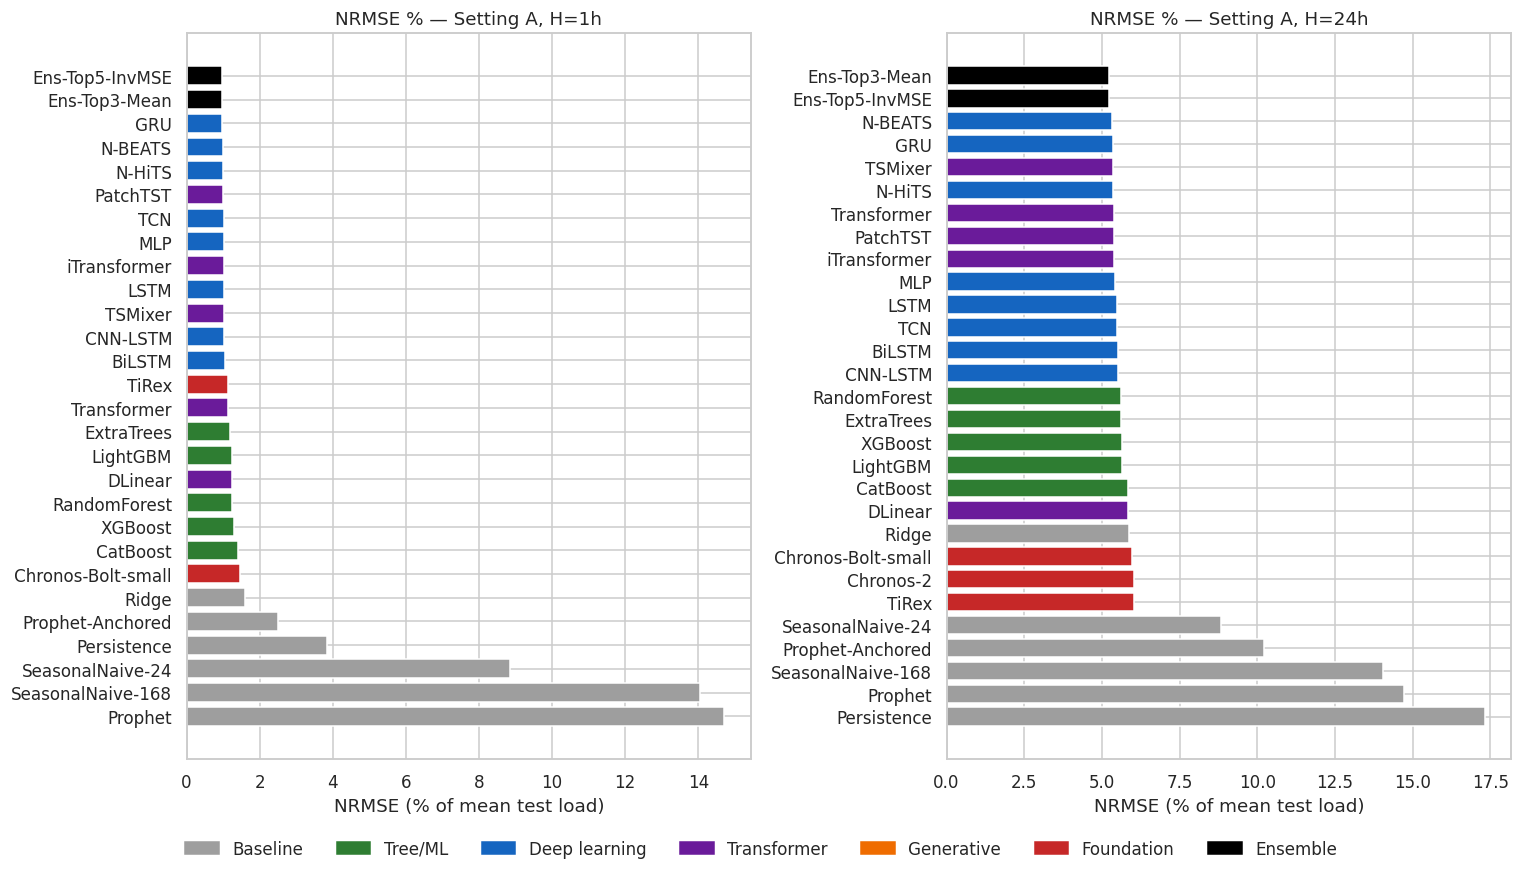

In [26]:
# ============================================================
# CELL 15 — Leaderboard
# ============================================================
RES = pd.read_csv(RES_PATH)
RES = RES[RES.dataset == DS_NAME]
COLS = ['model', 'family', 'RMSE', 'RMSE_std', 'MAE', 'NRMSE', 'NMAE', 'sMAPE', 'MASE', 'R2', 'val_RMSE', 'train_time_s', 'infer_ms_per_1k', 'n_params']
def leaderboard(setting, H):
    t = RES[(RES.setting == setting) & (RES.horizon == H)].sort_values('RMSE')[COLS].reset_index(drop=True)
    t['beats_snaive24'] = np.where(t['MASE'] < 1, 'YES', 'no')     # MASE<1 -> better than seasonal-naive-24
    t.index += 1; return t

for setting in CFG['SETTINGS']:
    for H in CFG['HORIZONS']:
        t = leaderboard(setting, H)
        if t.empty: print(f"\n(no results yet for setting {setting}, H={H})"); continue
        print(f"\n===== LEADERBOARD  {DS_NAME} | Setting {setting} | horizon {H}h | (lower = better; MASE<1 beats seasonal-naive-24) =====")
        # plain-text table: always readable, even where the styled table below does not render
        SHOW = ['model', 'family', 'RMSE', 'MAE', 'NRMSE', 'MASE', 'R2', 'val_RMSE', 'train_time_s', 'beats_snaive24']
        print(t[SHOW].round(4).to_string())
        print(f"\n--- best model per family (H={H}h) ---")
        print(t.drop_duplicates('family')[['family', 'model', 'RMSE', 'NRMSE', 'MASE']].round(4).to_string(index=False))
        try:
            display(t.round(4).style.background_gradient(subset=['RMSE'], cmap='RdYlGn_r').format(precision=4))
        except Exception as _e:
            print('(styled table not available:', _e, ')')
        t.round(5).to_csv(OUT / f'leaderboard_{DS_NAME}_{setting}_H{H}.csv')

# ---- bar chart of NRMSE by model ----
palette = {'Baseline': '#9e9e9e', 'Tree/ML': '#2e7d32', 'Deep learning': '#1565c0', 'Transformer': '#6a1b9a',
           'Generative': '#ef6c00', 'Foundation': '#c62828', 'Ensemble': '#000000'}
for setting in CFG['SETTINGS']:
    fig, axes = plt.subplots(1, len(CFG['HORIZONS']), figsize=(7 * len(CFG['HORIZONS']), 8), squeeze=False)
    for ax, H in zip(axes[0], CFG['HORIZONS']):
        t = leaderboard(setting, H).sort_values('NRMSE', ascending=False)
        if t.empty: continue
        ax.barh(t.model, t.NRMSE, color=[palette.get(f, '#333') for f in t.family])
        ax.set_title(f'NRMSE % — Setting {setting}, H={H}h'); ax.set_xlabel('NRMSE (% of mean test load)')
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
    fig.legend(handles, palette.keys(), loc='lower center', ncol=len(palette), frameon=False)
    plt.tight_layout(rect=(0, 0.04, 1, 1)); savefig(f'nrmse_bars_{setting}'); plt.show()

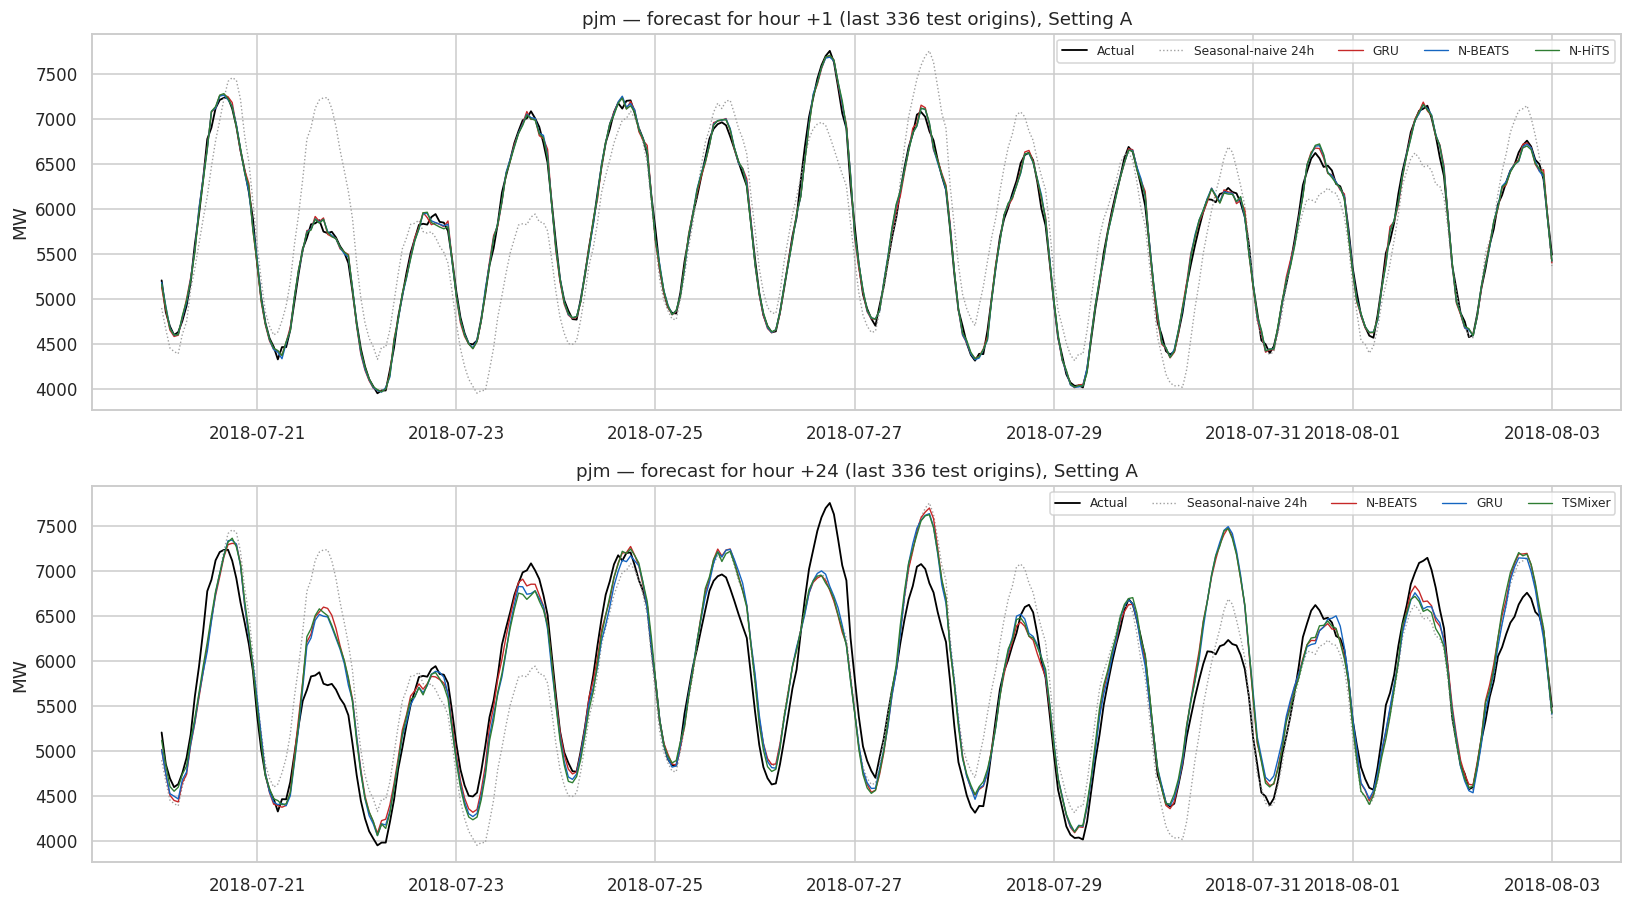

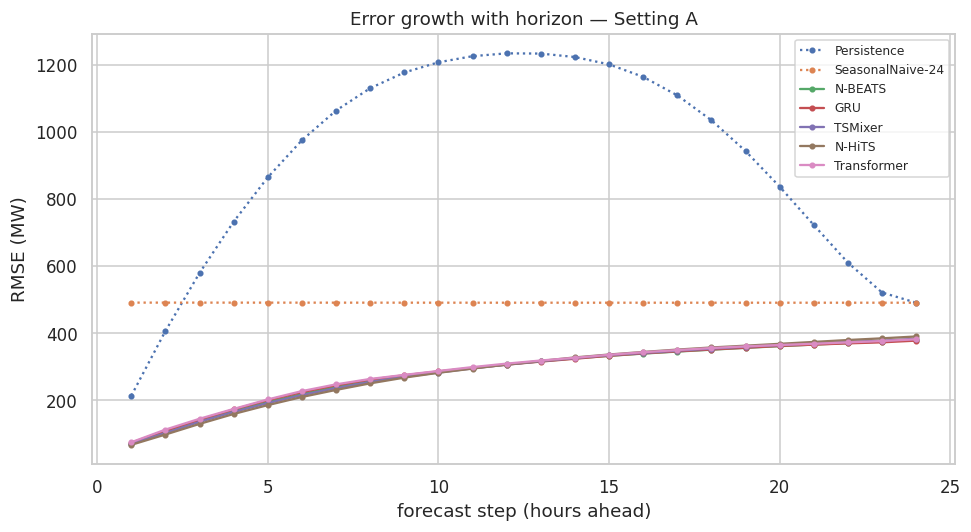

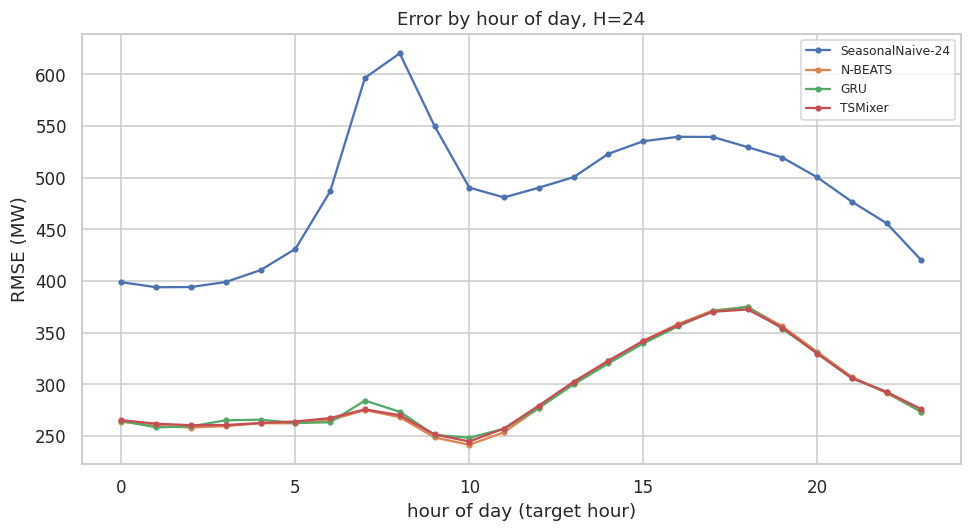

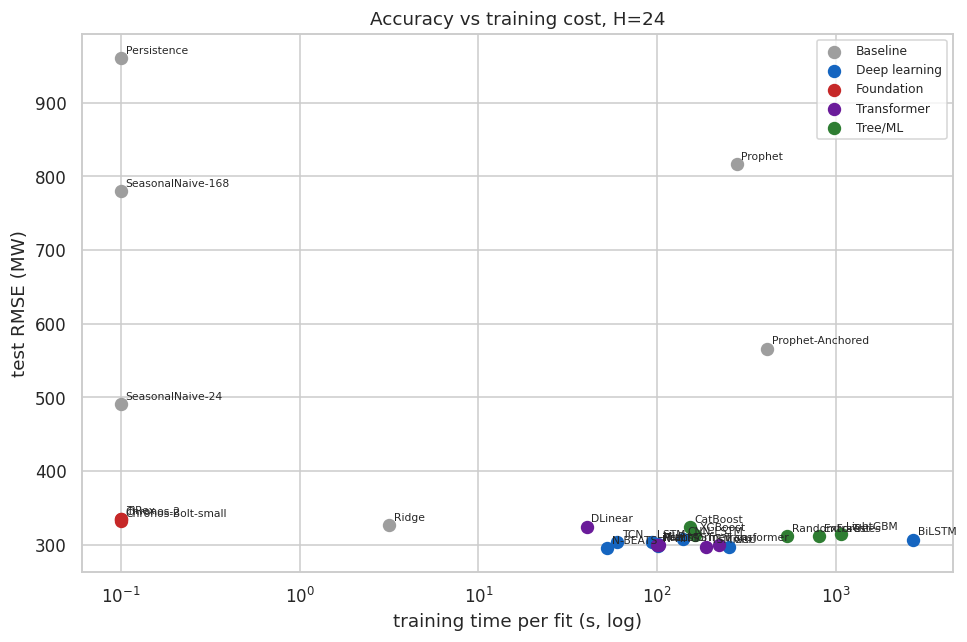

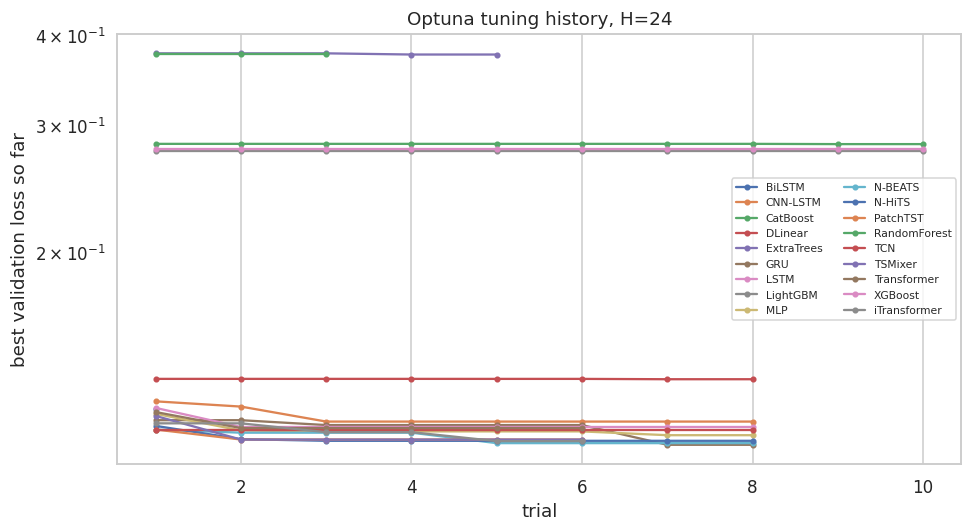

In [27]:
# ============================================================
# CELL 16 — Diagnostics: forecasts vs actual, error by horizon step, error by hour, efficiency, tuning history, importance
# ============================================================
MAIN_SETTING = CFG['SETTINGS'][0]; Hmax = max(CFG['HORIZONS']); bM = get_bundle(MAIN_SETTING)
def rows(setting, H): return RES[(RES.setting == setting) & (RES.horizon == H)]
def best_models(setting, H, n=3, exclude=('Ensemble', 'Baseline')):
    r = rows(setting, H); return list(r[~r.family.isin(exclude)].sort_values('RMSE').model.head(n))
def test_pred(setting, H, name): return np.load(pred_path(make_key(setting, H, name)))['test']
def have(setting, H, name): return pred_path(make_key(setting, H, name)).exists()    # model may have been skipped / not run

# ---- (1) actual vs predicted, last 14 days of the test set ----
fig, axes = plt.subplots(len(CFG['HORIZONS']), 1, figsize=(15, 4.2 * len(CFG['HORIZONS'])), squeeze=False)
for ax, H in zip(axes[:, 0], CFG['HORIZONS']):
    ot = get_origins(bM, 'test', 1, H); yt, mt = targets(bM, ot, H); tt = bM.idx[ot + H].to_numpy()
    n = min(336, len(ot)); sl = slice(-n, None)
    ax.plot(tt[sl], yt[sl, H-1], color='black', lw=1.2, label='Actual')
    if have(MAIN_SETTING, H, 'SeasonalNaive-24'):
        ax.plot(tt[sl], test_pred(MAIN_SETTING, H, 'SeasonalNaive-24')[sl, H-1], color='#9e9e9e', lw=0.9, ls=':', label='Seasonal-naive 24h')
    for nm, c in zip(best_models(MAIN_SETTING, H, 3), ['#c62828', '#1565c0', '#2e7d32']):
        ax.plot(tt[sl], test_pred(MAIN_SETTING, H, nm)[sl, H-1], color=c, lw=0.9, label=nm)
    ax.set_title(f'{DS_NAME} — forecast for hour +{H} (last {n} test origins), Setting {MAIN_SETTING}'); ax.set_ylabel(UNIT); ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); savefig('actual_vs_pred'); plt.show()

# ---- (2) RMSE by forecast step (longest horizon) ----
if Hmax > 1:
    ot = get_origins(bM, 'test', 1, Hmax); yt, mt = targets(bM, ot, Hmax); plt.figure(figsize=(9, 5))
    for nm in [m for m in ['Persistence', 'SeasonalNaive-24'] + best_models(MAIN_SETTING, Hmax, 5) if have(MAIN_SETTING, Hmax, m)]:
        p = test_pred(MAIN_SETTING, Hmax, nm)
        r = [np.sqrt(np.mean(((p - yt)[:, h][mt[:, h]])**2)) for h in range(Hmax)]
        plt.plot(range(1, Hmax + 1), r, marker='o', ms=3, label=nm, ls=':' if nm in ('Persistence', 'SeasonalNaive-24') else '-')
    plt.xlabel('forecast step (hours ahead)'); plt.ylabel(f'RMSE ({UNIT})'); plt.title(f'Error growth with horizon — Setting {MAIN_SETTING}')
    plt.legend(fontsize=8); plt.tight_layout(); savefig('rmse_by_step'); plt.show()

# ---- (3) error by hour of day (target hour) ----
ot = get_origins(bM, 'test', 1, Hmax); yt, mt = targets(bM, ot, Hmax); hrs = bM.idx.hour.values[ot[:, None] + np.arange(1, Hmax + 1)]
plt.figure(figsize=(9, 5))
for nm in [m for m in ['SeasonalNaive-24'] + best_models(MAIN_SETTING, Hmax, 3) if have(MAIN_SETTING, Hmax, m)]:
    e = (test_pred(MAIN_SETTING, Hmax, nm) - yt)**2
    plt.plot(range(24), [np.sqrt(np.mean(e[(hrs == h) & mt])) for h in range(24)], marker='o', ms=3, label=nm)
plt.xlabel('hour of day (target hour)'); plt.ylabel(f'RMSE ({UNIT})'); plt.title(f'Error by hour of day, H={Hmax}'); plt.legend(fontsize=8)
plt.tight_layout(); savefig('rmse_by_hour'); plt.show()

# ---- (4) accuracy vs cost ----
r = rows(MAIN_SETTING, Hmax); r = r[~r.family.isin(['Ensemble'])]
plt.figure(figsize=(9, 6))
for fam, g in r.groupby('family'):
    plt.scatter(g.train_time_s.fillna(0) + 0.1, g.RMSE, s=60, color=palette.get(fam, '#333'), label=fam)
    for _, x in g.iterrows(): plt.annotate(x.model, (x.train_time_s + 0.1 if pd.notna(x.train_time_s) else 0.1, x.RMSE), fontsize=7, xytext=(3, 3), textcoords='offset points')
plt.xscale('log'); plt.xlabel('training time per fit (s, log)'); plt.ylabel(f'test RMSE ({UNIT})'); plt.title(f'Accuracy vs training cost, H={Hmax}')
plt.legend(fontsize=8); plt.tight_layout(); savefig('accuracy_vs_cost'); plt.show()

# ---- (5) tuning history ----
plt.figure(figsize=(9, 5)); any_curve = False
for f in sorted((OUT / 'tuning').glob(f"{safe(DS_NAME)}_{MAIN_SETTING}_H{Hmax}_*_trials.csv")):
    t = pd.read_csv(f)
    if 'value' in t and t['value'].notna().any():
        plt.plot(t['number'] + 1, t['value'].cummin(), marker='.', label=f.stem.replace(f"{safe(DS_NAME)}_{MAIN_SETTING}_H{Hmax}_", '').replace('_trials', '')); any_curve = True
if any_curve:
    plt.yscale('log'); plt.xlabel('trial'); plt.ylabel('best validation loss so far'); plt.title(f'Optuna tuning history, H={Hmax}')
    plt.legend(fontsize=7, ncol=2); plt.tight_layout(); savefig('tuning_history'); plt.show()
else: plt.close()

# ---- (6) tree feature importance (if available) ----
for nm in ['XGBoost', 'LightGBM']:
    f = OUT / 'artifacts' / (safe(make_key(MAIN_SETTING, Hmax, nm)) + '_importance.csv')
    if f.exists():
        imp = pd.read_csv(f).sort_values('importance', ascending=False).head(20)
        plt.figure(figsize=(8, 6)); sns.barplot(x='importance', y='feature', data=imp, color='#2e7d32')
        plt.title(f'{nm} — top-20 feature importance (step +1 model)'); plt.tight_layout(); savefig(f'importance_{nm}'); plt.show(); break

In [28]:
# ============================================================
# CELL 17 — Statistical significance (Diebold–Mariano) + best-model summary
# ============================================================
def dm_test(e1, e2, H):
    """H0: equal squared-error accuracy. stat>0 => model 1 WORSE than model 2.
    Newey-West HAC variance with lag = max(H-1, round(n^(1/3))) (v9). The old lag H-1 means NO correction at H=1, although
    hourly forecast errors are serially correlated; in a simulation that inflated false 'significant' verdicts from 5% to 24-52%."""
    d = np.nanmean(e1**2 - e2**2, axis=1); d = d[np.isfinite(d)]; n = len(d); dbar = d.mean(); dc = d - dbar
    L = max(H - 1, int(round(n ** (1 / 3))))
    var = np.sum(dc * dc) / n
    for k in range(1, L + 1): var += 2 * (1 - k / (L + 1)) * np.sum(dc[k:] * dc[:-k]) / n
    stat = dbar / math.sqrt(max(var, 1e-18) / n); p = math.erfc(abs(stat) / math.sqrt(2)); return stat, p

for setting in CFG['SETTINGS']:
    for H in CFG['HORIZONS']:
        b = get_bundle(setting); ot = get_origins(b, 'test', 1, H); yt, mt = targets(b, ot, H)
        r = rows(setting, H).sort_values('RMSE'); top = list(r.model.head(6))
        top = [m for m in top if have(setting, H, m)]
        if len(top) < 2: print(f"\nDiebold–Mariano | Setting {setting} | H={H}h: need at least 2 models with saved predictions — skipped"); continue
        best = top[0]
        err = lambda nm: np.where(mt, test_pred(setting, H, nm) - yt, np.nan)
        out = []
        for nm in top[1:]:
            s, p = dm_test(err(nm), err(best), H); out.append(dict(vs_best=nm, DM_stat=round(s, 2), p_value=round(p, 4),
                                                                   significantly_worse_at_5pct=bool(p < 0.05 and s > 0)))
        print(f"\nDiebold–Mariano | Setting {setting} | H={H}h | best = {best}")
        display(pd.DataFrame(out))

print("\n" + "=" * 70 + "\nBEST INDIVIDUAL MODEL PER SETTING/HORIZON (ensembles excluded)\n" + "=" * 70)
summary = {}
for setting in CFG['SETTINGS']:
    for H in CFG['HORIZONS']:
        r = rows(setting, H); r = r[r.family != 'Ensemble'].sort_values('RMSE')
        if r.empty: continue
        x = r.iloc[0]; sn = r[r.model == 'SeasonalNaive-24']
        gain = f"{100 * (1 - x.RMSE / sn.iloc[0].RMSE):.1f}% lower RMSE than seasonal-naive-24" if len(sn) else ""
        print(f"[{setting}] H={H:<3} → {x.model:<18} RMSE={x.RMSE:.4f} {UNIT}  NRMSE={x.NRMSE:.2f}%  MASE={x.MASE:.3f}   {gain}")
        summary[f'{setting}_H{H}'] = dict(model=x.model, RMSE=x.RMSE, NRMSE=x.NRMSE, MASE=x.MASE, best_params=json.loads(x.best_params))
json.dump(summary, open(OUT / f'best_models_{DS_NAME}.json', 'w'), indent=2, default=str)


Diebold–Mariano | Setting A | H=1h | best = Ens-Top5-InvMSE


,vs_best,DM_stat,p_value,significantly_worse_at_5pct
0,Ens-Top3-Mean,0.40,0.6904,False
1,GRU,8.43,0.0000,True
2,N-BEATS,10.60,0.0000,True
3,N-HiTS,10.41,0.0000,True
4,PatchTST,15.23,0.0000,True



Diebold–Mariano | Setting A | H=24h | best = Ens-Top3-Mean


,vs_best,DM_stat,p_value,significantly_worse_at_5pct
0,Ens-Top5-InvMSE,0.27,0.7867,False
1,N-BEATS,6.50,0.0000,True
2,GRU,6.08,0.0000,True
3,TSMixer,4.30,0.0000,True
4,N-HiTS,3.30,0.0010,True



BEST INDIVIDUAL MODEL PER SETTING/HORIZON (ensembles excluded)
[A] H=1   → GRU                RMSE=54.4125 MW  NRMSE=0.98%  MASE=0.118   88.9% lower RMSE than seasonal-naive-24
[A] H=24  → N-BEATS            RMSE=295.5799 MW  NRMSE=5.33%  MASE=0.598   39.8% lower RMSE than seasonal-naive-24


## Paper-ready tables (new in v8)
The next cell turns the saved results into tables you can paste into the paper. It writes **CSV + Markdown + LaTeX** files to `<results folder>/paper_tables/`:
- **Table 1 (full):** every model per horizon, with RMSE/MAE in the dataset's unit, NRMSE %, MASE, R², *skill vs seasonal-naive-24*, and a **Diebold–Mariano marker** (`best` / `n.s.` = not significantly worse than the best / `sig. worse`).
- **Table 2 (headline summary):** best single model, best ensemble, and the Persistence / seasonal-naive references, with % improvement.
- **Table 3 (best per family).**
- **`paper_summary_<dataset>.txt`:** a short auto-written results paragraph (numbers filled in from your run).

LaTeX tables use `booktabs` — add `\usepackage{booktabs}` to your preamble.

In [29]:
# ============================================================
# CELL 17b — PAPER-READY TABLES  (CSV + Markdown + LaTeX in <OUT>/paper_tables/)
# ============================================================
PAPER = OUT / 'paper_tables'; PAPER.mkdir(exist_ok=True)
RES_P = pd.read_csv(RES_PATH); RES_P = RES_P[RES_P.dataset == DS_NAME]
NAIVE = {'Persistence', 'SeasonalNaive-24', 'SeasonalNaive-168'}

def _md_table(df):
    cols = list(df.columns)
    lines = ['| ' + ' | '.join(map(str, cols)) + ' |', '|' + '|'.join(['---'] * len(cols)) + '|']
    for _, r in df.iterrows(): lines.append('| ' + ' | '.join('' if pd.isna(v) else str(v) for v in r.values) + ' |')
    return '\n'.join(lines)

def _tex(s):
    s = str(s)
    for a, b_ in [('\\', r'\textbackslash{}'), ('&', r'\&'), ('%', r'\%'), ('_', r'\_'), ('#', r'\#'),
                  ('\u00b1', r'$\pm$'), ('\u00b2', r'$^2$'), ('\u00b0', r'$^\circ$'), ('\u2020', r'$^\dagger$')]:
        s = s.replace(a, b_)
    return s

def _latex_table(df, caption, label, n_text):
    cols = list(df.columns)
    out = [r'\begin{table}[ht]', r'\centering', r'\small', r'\caption{' + _tex(caption) + '}', r'\label{' + label + '}',
           r'\begin{tabular}{' + 'l' * n_text + 'r' * (len(cols) - n_text) + '}', r'\toprule',
           ' & '.join(_tex(c) for c in cols) + r' \\', r'\midrule']
    for _, r in df.iterrows(): out.append(' & '.join('' if pd.isna(v) else _tex(v) for v in r.values) + r' \\')
    return '\n'.join(out + [r'\bottomrule', r'\end{tabular}', r'\end{table}'])

def _save(df, stem, caption, n_text):
    df.to_csv(PAPER / f'{stem}.csv', index=False)
    (PAPER / f'{stem}.md').write_text(_md_table(df))
    (PAPER / f'{stem}.tex').write_text(_latex_table(df, caption, 'tab:' + stem, n_text))

def _test_info(b):
    return (f"Test period {b.idx[b.n_tr + b.n_val]:%Y-%m-%d} to {b.idx[-1]:%Y-%m-%d} ({b.n_te} h); "
            f"mean test load {b.mean_load:.1f} {UNIT}")

def paper_full(setting, H):
    t = RES_P[(RES_P.setting == setting) & (RES_P.horizon == H)].sort_values('RMSE').reset_index(drop=True)
    if t.empty: return None
    b = get_bundle(setting); ot = get_origins(b, 'test', 1, H); yt, mt = targets(b, ot, H)
    best = t.model.iloc[0]; dec = 2 if b.mean_load >= 50 else 4
    sn = t[t.model == 'SeasonalNaive-24']; sn_rmse = float(sn.RMSE.iloc[0]) if len(sn) else np.nan
    err = lambda nm: np.where(mt, test_pred(setting, H, nm) - yt, np.nan)
    marks = []
    for nm in t.model:
        if nm == best: marks.append('best')
        elif not (have(setting, H, nm) and have(setting, H, best)): marks.append('-')
        else:
            s, p = dm_test(err(nm), err(best), H); marks.append('sig. worse' if (p < 0.05 and s > 0) else 'n.s.')
    rm = [f"{r:.{dec}f}" + (f" \u00b1 {s:.{dec}f}" if pd.notna(s) and s > 0 else '') for r, s in zip(t.RMSE, t.RMSE_std)]
    out = pd.DataFrame({'Rank': np.arange(1, len(t) + 1), 'Model': t.model, 'Family': t.family,
                        f'RMSE ({UNIT})': rm, f'MAE ({UNIT})': t.MAE.map(lambda x: f"{x:.{dec}f}"),
                        'NRMSE (%)': t.NRMSE.map(lambda x: f"{x:.2f}"), 'MASE': t.MASE.map(lambda x: f"{x:.3f}"),
                        'R\u00b2': t.R2.map(lambda x: f"{x:.3f}"),
                        'Skill vs SN-24 (%)': [f"{100 * (1 - r / sn_rmse):.1f}" if np.isfinite(sn_rmse) else '' for r in t.RMSE],
                        'vs best (DM, 5%)': marks})
    return out, t, b, dec

def paper_summary(setting):
    recs = []
    for H in CFG['HORIZONS']:
        t = RES_P[(RES_P.setting == setting) & (RES_P.horizon == H)]
        if t.empty: continue
        b = get_bundle(setting); dec = 2 if b.mean_load >= 50 else 4
        ref = lambda m: float(t[t.model == m].RMSE.iloc[0]) if (t.model == m).any() else np.nan
        sn, pe = ref('SeasonalNaive-24'), ref('Persistence')
        picks = [('Best single model', t[(t.family != 'Ensemble') & (~t.model.isin(NAIVE))].sort_values('RMSE')),
                 ('Best ensemble', t[t.family == 'Ensemble'].sort_values('RMSE')),
                 ('Persistence', t[t.model == 'Persistence']), ('Seasonal-naive-24', t[t.model == 'SeasonalNaive-24'])]
        for role, sub in picks:
            if sub.empty: continue
            x = sub.iloc[0]
            recs.append({'Horizon (h)': H, 'Role': role, 'Model': x.model, f'RMSE ({UNIT})': f"{x.RMSE:.{dec}f}",
                         'NRMSE (%)': f"{x.NRMSE:.2f}", 'MASE': f"{x.MASE:.3f}",
                         'vs Persistence (%)': f"{100 * (1 - x.RMSE / pe):.1f}" if np.isfinite(pe) else '',
                         'vs SN-24 (%)': f"{100 * (1 - x.RMSE / sn):.1f}" if np.isfinite(sn) else ''})
    return pd.DataFrame(recs)

def paper_by_family(setting):
    recs = []
    for H in CFG['HORIZONS']:
        t = RES_P[(RES_P.setting == setting) & (RES_P.horizon == H)].sort_values('RMSE')
        if t.empty: continue
        dec = 2 if get_bundle(setting).mean_load >= 50 else 4
        for _, x in t.drop_duplicates('family').iterrows():
            recs.append({'Horizon (h)': H, 'Family': x.family, 'Model': x.model, f'RMSE ({UNIT})': f"{x.RMSE:.{dec}f}",
                         'NRMSE (%)': f"{x.NRMSE:.2f}", 'MASE': f"{x.MASE:.3f}"})
    return pd.DataFrame(recs)

para = []
for setting in CFG['SETTINGS']:
    b = get_bundle(setting)
    tinfo = _test_info(b)
    for H in CFG['HORIZONS']:
        res = paper_full(setting, H)
        if res is None: continue
        full_t, raw_t, _, dec = res
        _save(full_t, f'{DS_NAME}_{setting}_H{H}_full', f'{DS_NAME}, Setting {setting}, horizon {H} h. {tinfo}. '
              f'Skill = RMSE reduction vs seasonal-naive-24; DM = Diebold-Mariano test vs the best model.', 3)
        n_ns = int((full_t['vs best (DM, 5%)'] == 'n.s.').sum())
        top = raw_t[(raw_t.family != 'Ensemble') & (~raw_t.model.isin(NAIVE))].iloc[0]
        _best = raw_t.model.iloc[0]
        _tie = (f"{n_ns} other model(s) were not significantly worse than the overall best ({_best}) under a Diebold-Mariano "
                f"test at the 5% level, so the ranking among these models should be read as a statistical tie."
                if n_ns > 0 else
                f"Every other model was significantly worse than the overall best ({_best}) under a Diebold-Mariano test "
                f"at the 5% level.")
        para.append(f"At a {H}-hour horizon the best individual model on {DS_NAME} (Setting {setting}) was {top.model} "
                    f"(RMSE {top.RMSE:.{dec}f} {UNIT}, NRMSE {top.NRMSE:.2f}%, MASE {top.MASE:.3f}). " + _tie)
    summ = paper_summary(setting); fam = paper_by_family(setting)
    _save(summ, f'{DS_NAME}_{setting}_summary', f'Headline results, {DS_NAME}, Setting {setting}. {tinfo}.', 3)
    _save(fam, f'{DS_NAME}_{setting}_by_family', f'Best model per family, {DS_NAME}, Setting {setting}.', 3)
    if setting == CFG['SETTINGS'][0]:
        print(f"===== TABLE 2 — headline summary ({DS_NAME}, Setting {setting}) =====\n{tinfo}\n")
        print(_md_table(summ))
        print(f"\n===== TABLE 3 — best model per family =====\n"); print(_md_table(fam))
(PAPER / f'paper_summary_{DS_NAME}.txt').write_text(f"{_test_info(get_bundle(CFG['SETTINGS'][0]))}.\n\n" + "\n\n".join(para))
print("\n===== AUTO-WRITTEN RESULTS PARAGRAPH =====\n" + "\n\n".join(para))
print(f"\nFiles written to: {PAPER}  (Table 1 per horizon: *_full.*, plus *_summary.* and *_by_family.*; formats .csv/.md/.tex)")

===== TABLE 2 — headline summary (pjm, Setting A) =====
Test period 2015-04-27 to 2018-08-03 (28647 h); mean test load 5547.8 MW

| Horizon (h) | Role | Model | RMSE (MW) | NRMSE (%) | MASE | vs Persistence (%) | vs SN-24 (%) |
|---|---|---|---|---|---|---|---|
| 1 | Best single model | GRU | 54.41 | 0.98 | 0.118 | 74.6 | 88.9 |
| 1 | Best ensemble | Ens-Top5-InvMSE | 53.64 | 0.97 | 0.116 | 74.9 | 89.1 |
| 1 | Persistence | Persistence | 213.89 | 3.86 | 0.474 | 0.0 | 56.4 |
| 1 | Seasonal-naive-24 | SeasonalNaive-24 | 490.69 | 8.84 | 1.043 | -129.4 | 0.0 |
| 24 | Best single model | N-BEATS | 295.58 | 5.33 | 0.598 | 69.2 | 39.8 |
| 24 | Best ensemble | Ens-Top3-Mean | 290.57 | 5.24 | 0.585 | 69.7 | 40.8 |
| 24 | Persistence | Persistence | 960.52 | 17.31 | 2.048 | 0.0 | -95.8 |
| 24 | Seasonal-naive-24 | SeasonalNaive-24 | 490.64 | 8.84 | 1.042 | 48.9 | 0.0 |

===== TABLE 3 — best model per family =====

| Horizon (h) | Family | Model | RMSE (MW) | NRMSE (%) | MASE |
|---|---|---|---|-

In [30]:
# ============================================================
# CELL 18 — Leakage ablation (Setting A vs B)  →  quantifies how much the OLD setup flattered the results
# Setting B feeds the covariates measured DURING the target hour (Global_intensity, Voltage, sub-meters ...).
# ============================================================
ABL_MODELS = ['Ridge', 'XGBoost', 'LSTM']
ABL_MODELS = [m for m in ABL_MODELS if m in RUNNERS]
if len(DS['covariates']) == 0:
    print("This dataset has no covariates — ablation not applicable.")
else:
    for st in ['A', 'B']: run_experiment(st, 1, models=ABL_MODELS)
    RES = pd.read_csv(RES_PATH); RES = RES[RES.dataset == DS_NAME]
    a = RES[(RES.setting == 'A') & (RES.horizon == 1) & RES.model.isin(ABL_MODELS)].set_index('model')
    bb = RES[(RES.setting == 'B') & (RES.horizon == 1) & RES.model.isin(ABL_MODELS)].set_index('model')
    tbl = pd.DataFrame({'RMSE_A_forecast': a.RMSE, 'RMSE_B_leaky': bb.RMSE, 'NRMSE_A_%': a.NRMSE, 'NRMSE_B_%': bb.NRMSE}).dropna()
    tbl['error_reduction_from_leakage_%'] = 100 * (1 - tbl.RMSE_B_leaky / tbl.RMSE_A_forecast)
    print("\nSame models, same data — only difference: inputs include covariates measured in the target hour (B) or not (A):")
    display(tbl.round(4)); tbl.round(5).to_csv(OUT / f'leakage_ablation_{DS_NAME}.csv')
    print("→ B numbers are NOT achievable in real forecasting (the covariates are unknown at forecast time).")

This dataset has no covariates — ablation not applicable.


Datasets with results (Setting A, mode STANDARD): ['pjm']
-> only one dataset so far. Run the other datasets with the same RUN_MODE (see PRESETS in Cell 2), then re-run this cell.

1) Dataset difficulty — NRMSE (%) of naive references vs. the best single model:


Persistence  SeasonalNaive-24  best_single_model  \
dataset horizon                                                     
pjm     1               3.86              8.84               0.98   
        24             17.31              8.84               5.33   

                 skill_vs_seasonal_naive_%  
dataset horizon                             
pjm     1                            88.91  
        24                           39.76

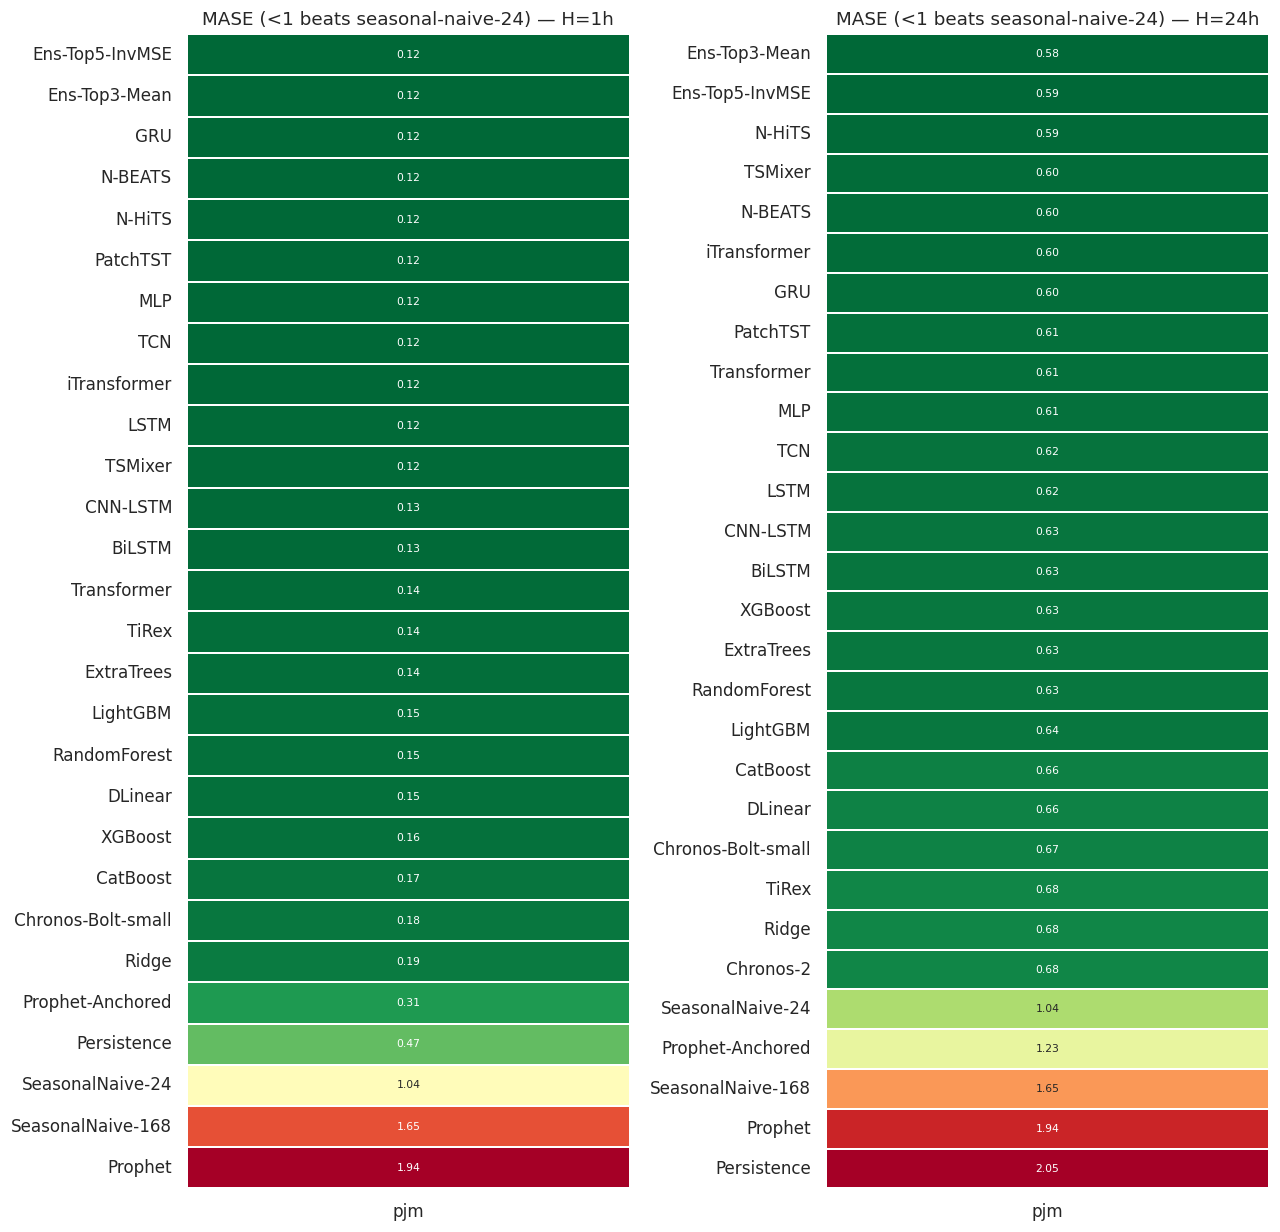

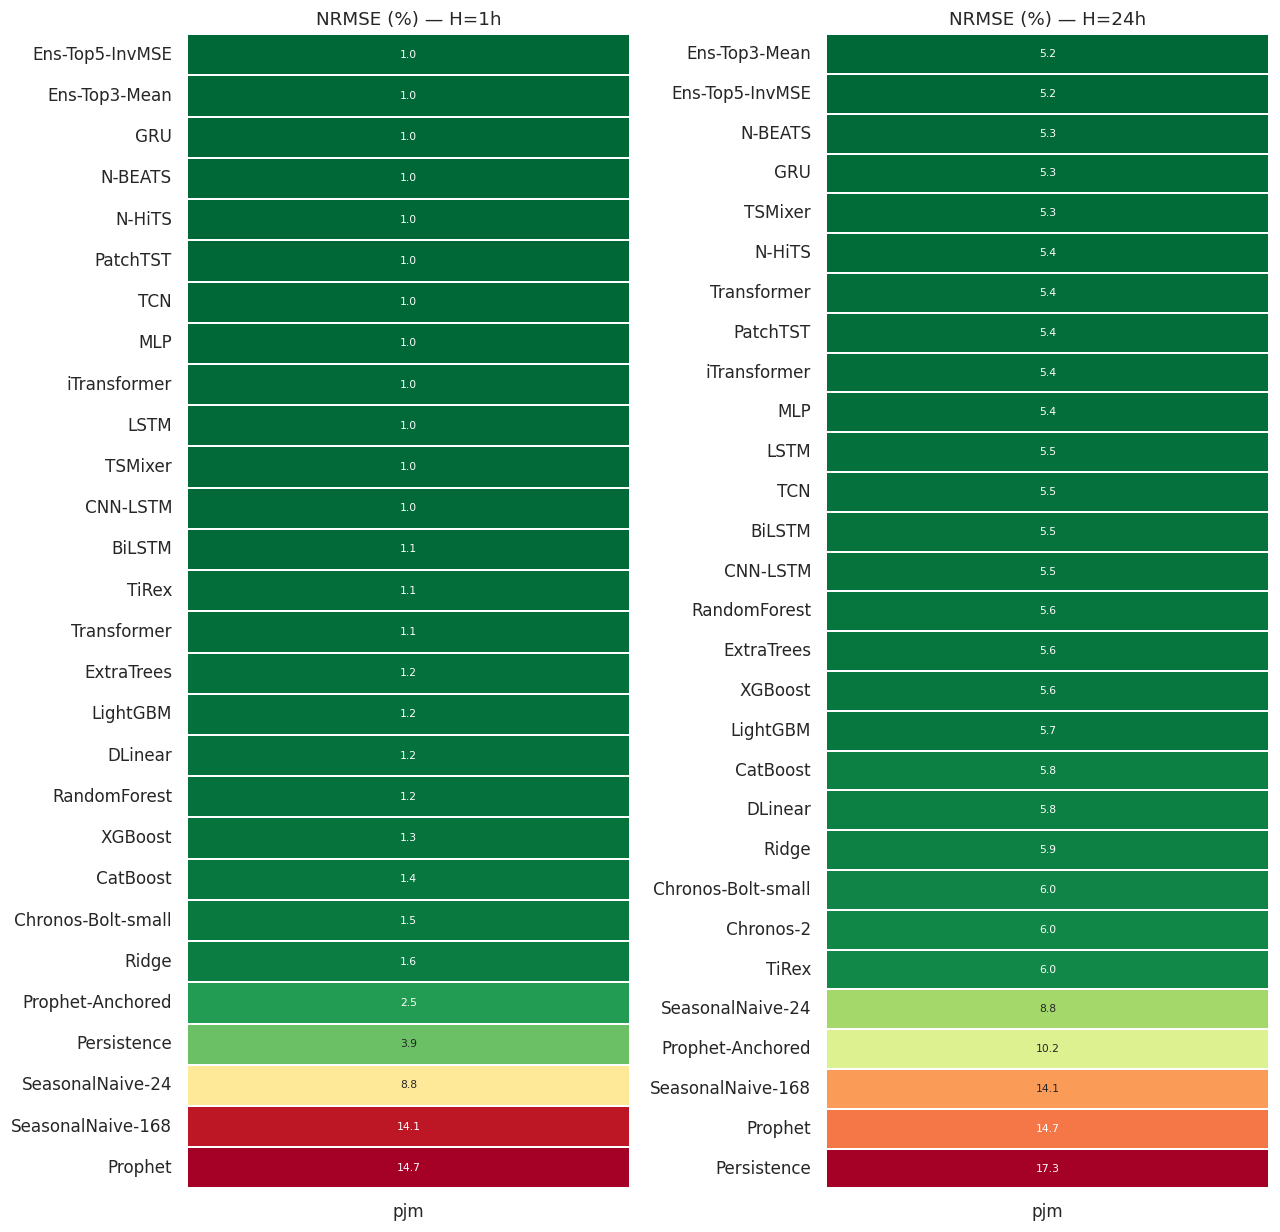


3) Top models by mean rank across datasets — H=1h (only models present on at least 1 of 1 datasets):


,model,family,datasets,mean_rank,mean_rel_RMSE,wins
0,GRU,Deep learning,1,1.0,1.000,1
1,N-BEATS,Deep learning,1,2.0,1.008,0
2,N-HiTS,Deep learning,1,3.0,1.011,0
3,PatchTST,Transformer,1,4.0,1.023,0
4,TCN,Deep learning,1,5.0,1.038,0
5,MLP,Deep learning,1,6.0,1.039,0
6,iTransformer,Transformer,1,7.0,1.041,0
7,LSTM,Deep learning,1,8.0,1.044,0
8,TSMixer,Transformer,1,9.0,1.050,0
9,CNN-LSTM,Deep learning,1,10.0,1.059,0



3) Top models by mean rank across datasets — H=24h (only models present on at least 1 of 1 datasets):


,model,family,datasets,mean_rank,mean_rel_RMSE,wins
0,N-BEATS,Deep learning,1,1.0,1.000,1
1,GRU,Deep learning,1,2.0,1.002,0
2,TSMixer,Transformer,1,3.0,1.002,0
3,N-HiTS,Deep learning,1,4.0,1.006,0
4,Transformer,Transformer,1,5.0,1.012,0
5,PatchTST,Transformer,1,6.0,1.012,0
6,iTransformer,Transformer,1,7.0,1.014,0
7,MLP,Deep learning,1,8.0,1.017,0
8,LSTM,Deep learning,1,9.0,1.027,0
9,TCN,Deep learning,1,10.0,1.028,0


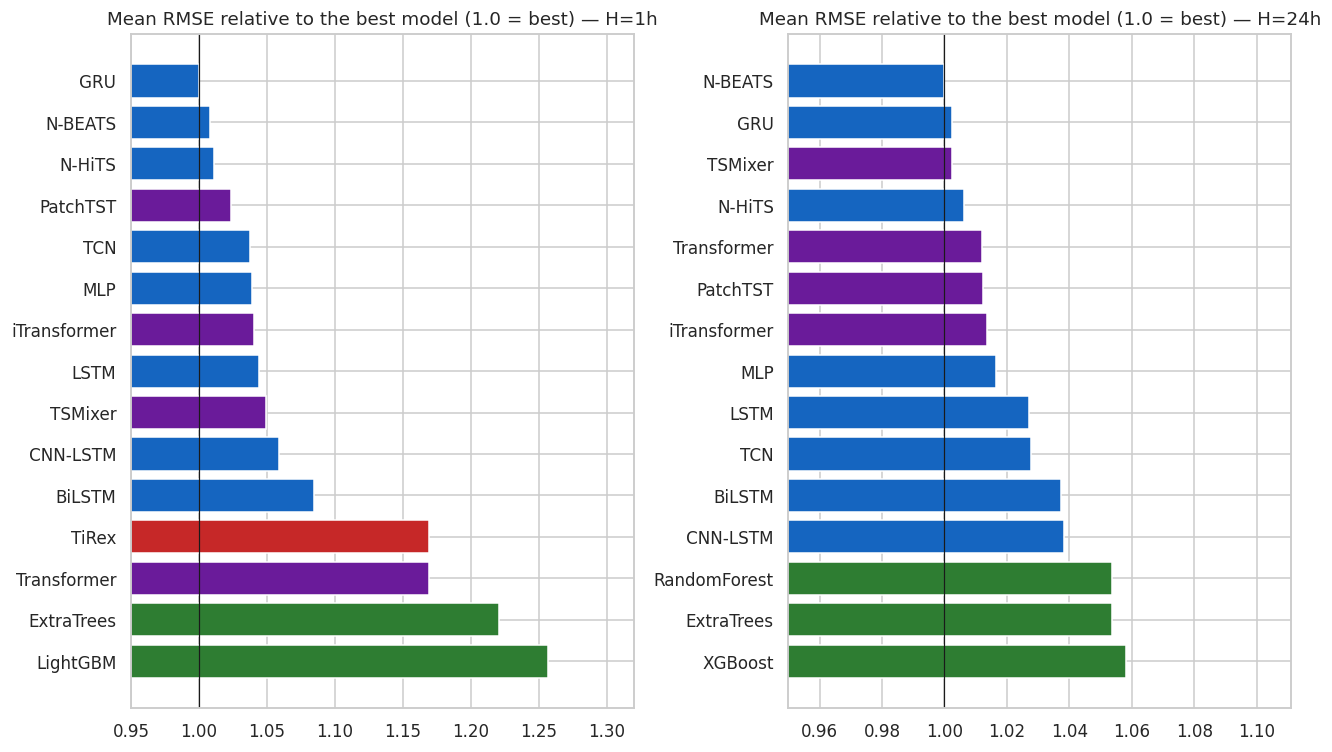


4) Best model of each family, RMSE relative to the best single model (1.00 = that family has the overall best model):


horizon,1,24
dataset,pjm,pjm
family,,
Baseline,1.624,1.103
Deep learning,1.000,1.000
Foundation,1.169,1.121
Transformer,1.023,1.002
Tree/ML,1.221,1.054



5) Ensemble gain over the best single model (%, positive = ensemble better):


ensemble_gain_over_best_single_%
dataset horizon                                  
pjm     1                                    1.42
        24                                   1.69


Saved tables and figures to /kaggle/working/aifs_results_STANDARD/cross_dataset
H=1h: best mean rank = GRU (1.00); lowest mean relative RMSE = GRU (1.000)
H=24h: best mean rank = N-BEATS (1.00); lowest mean relative RMSE = N-BEATS (1.000)


In [31]:
# ============================================================
# CELL 19 — CROSS-DATASET COMPARISON  (v10)
# Reads EVERY dataset that has results in this run mode's folder (<OUT>/results.csv) and compares models across datasets.
# Workflow: run the notebook once per dataset (PRESET or CFG['DATASET']), always with the same RUN_MODE, then run this cell.
# It is self-contained: after a kernel restart, run Cell 0, Cell 2 and Cell 3 (for OUT) and then this cell.
# ============================================================
palette = globals().get('palette') or {'Baseline': '#9e9e9e', 'Tree/ML': '#2e7d32', 'Deep learning': '#1565c0', 'Transformer': '#6a1b9a',
                                        'Generative': '#ef6c00', 'Foundation': '#c62828', 'Ensemble': '#000000'}
CROSS = OUT / 'cross_dataset'; CROSS.mkdir(exist_ok=True)
_all = pd.read_csv(OUT / 'results.csv')
_set = CFG['SETTINGS'][0]
_d = _all[(_all.setting == _set)].copy()
_ds = sorted(_d.dataset.unique()); _hs = sorted(_d.horizon.unique())
print(f"Datasets with results (Setting {_set}, mode {CFG['RUN_MODE']}): {_ds}")
if len(_ds) < 2:
    print("-> only one dataset so far. Run the other datasets with the same RUN_MODE (see PRESETS in Cell 2), then re-run this cell.")

# ---- 1) dataset difficulty: how hard is each dataset for the naive references? ----
_ref = _d[_d.model.isin(['Persistence', 'SeasonalNaive-24'])].pivot_table(index=['dataset', 'horizon'], columns='model', values='NRMSE')
_best = _d[~_d.family.isin(['Ensemble'])].groupby(['dataset', 'horizon']).NRMSE.min().rename('best_single_model')
_diff = _ref.join(_best); _diff['skill_vs_seasonal_naive_%'] = 100 * (1 - _diff['best_single_model'] / _diff['SeasonalNaive-24'])
print("\n1) Dataset difficulty — NRMSE (%) of naive references vs. the best single model:")
display(_diff.round(2)); _diff.round(3).to_csv(CROSS / 'dataset_difficulty.csv')

# ---- 2) heat-maps: models x datasets (one panel per horizon). MASE is comparable across datasets; NRMSE is not scale-free in meaning ----
for _metric, _title in [('MASE', 'MASE (<1 beats seasonal-naive-24)'), ('NRMSE', 'NRMSE (%)')]:
    fig, axes = plt.subplots(1, len(_hs), figsize=(5.4 * len(_hs) + 1, 0.34 * max(10, _d.model.nunique()) + 1.5), squeeze=False)
    for ax, H in zip(axes[0], _hs):
        P = _d[_d.horizon == H].pivot_table(index='model', columns='dataset', values=_metric)
        P = P.loc[P.mean(axis=1).sort_values().index]
        sns.heatmap(P, annot=True, fmt='.2f' if _metric == 'MASE' else '.1f', cmap='RdYlGn_r', cbar=False, ax=ax, annot_kws={'size': 7}, linewidths=.3)
        ax.set_title(f'{_title} — H={H}h'); ax.set_ylabel(''); ax.set_xlabel('')
        P.round(3).to_csv(CROSS / f'matrix_{_metric}_H{H}.csv')
    plt.tight_layout(); plt.savefig(CROSS / f'heatmap_{_metric}.png', dpi=150, bbox_inches='tight'); plt.show()

# ---- 3) average rank and relative error across datasets (individual models; ensembles shown separately) ----
_ind = _d[~_d.family.isin(['Ensemble'])].copy()
_ind['rank'] = _ind.groupby(['dataset', 'horizon']).RMSE.rank(method='min')
_ind['rel_rmse'] = _ind.RMSE / _ind.groupby(['dataset', 'horizon']).RMSE.transform('min')      # 1.00 = best single model on that dataset/horizon
_rows = []
for H in _hs:
    g = _ind[_ind.horizon == H].groupby('model').agg(datasets=('dataset', 'nunique'), mean_rank=('rank', 'mean'), mean_rel_RMSE=('rel_rmse', 'mean'),
                                                     wins=('rank', lambda r: int((r == 1).sum())), family=('family', 'first')).reset_index()
    g['horizon'] = H; _rows.append(g)
_rank = pd.concat(_rows).sort_values(['horizon', 'mean_rank'])
need = max(1, int(np.ceil(0.5 * len(_ds))))
for H in _hs:
    t = _rank[(_rank.horizon == H) & (_rank.datasets >= need)].head(15)
    print(f"\n3) Top models by mean rank across datasets — H={H}h (only models present on at least {need} of {len(_ds)} datasets):")
    display(t[['model', 'family', 'datasets', 'mean_rank', 'mean_rel_RMSE', 'wins']].round(3).reset_index(drop=True))
_rank.round(4).to_csv(CROSS / 'average_rank.csv', index=False)

fig, axes = plt.subplots(1, len(_hs), figsize=(6 * len(_hs), 7), squeeze=False)
for ax, H in zip(axes[0], _hs):
    t = _rank[(_rank.horizon == H) & (_rank.datasets >= need)].head(15).iloc[::-1]
    ax.barh(t.model, t.mean_rel_RMSE, color=[palette.get(f, '#333') for f in t.family]); ax.axvline(1, color='k', lw=.8)
    ax.set_title(f'Mean RMSE relative to the best model (1.0 = best) — H={H}h'); ax.set_xlim(left=0.95)
plt.tight_layout(); plt.savefig(CROSS / 'relative_rmse.png', dpi=150, bbox_inches='tight'); plt.show()

# ---- 4) which family wins where? best single model per family, relative to the overall best ----
_fam = _ind.groupby(['dataset', 'horizon', 'family']).rel_rmse.min().reset_index().pivot_table(index=['family'], columns=['horizon', 'dataset'], values='rel_rmse')
print("\n4) Best model of each family, RMSE relative to the best single model (1.00 = that family has the overall best model):")
display(_fam.round(3)); _fam.round(4).to_csv(CROSS / 'family_summary.csv')

# ---- 5) ensembles: gain over the best single model, per dataset and horizon ----
_ens = _d[_d.family == 'Ensemble'].groupby(['dataset', 'horizon']).RMSE.min()
_gain = (100 * (1 - _ens / _ind.groupby(['dataset', 'horizon']).RMSE.min())).rename('ensemble_gain_over_best_single_%')
print("\n5) Ensemble gain over the best single model (%, positive = ensemble better):"); display(_gain.round(2).to_frame())
_gain.round(3).to_csv(CROSS / 'ensemble_gain.csv')

# ---- 6) LaTeX tables for the manuscript ----
for H in _hs:
    t = _rank[(_rank.horizon == H) & (_rank.datasets >= need)].head(12)[['model', 'family', 'datasets', 'mean_rank', 'mean_rel_RMSE', 'wins']]
    (CROSS / f'cross_dataset_rank_H{H}.tex').write_text(t.to_latex(index=False, float_format='%.2f', caption=f'Models ranked by mean rank across datasets, horizon {H} h.', label=f'tab:cross{H}'))
print(f"\nSaved tables and figures to {CROSS}")
for H in _hs:
    t = _rank[(_rank.horizon == H) & (_rank.datasets >= need)]
    if len(t): print(f"H={H}h: best mean rank = {t.iloc[0].model} ({t.iloc[0].mean_rank:.2f}); lowest mean relative RMSE = {t.sort_values('mean_rel_RMSE').iloc[0].model} ({t.sort_values('mean_rel_RMSE').iloc[0].mean_rel_RMSE:.3f})")

In [32]:
# ============================================================
# CELL LAST — Package the small outputs (tables, figures, results.csv) for download
# ============================================================
import zipfile
z = WORK / f'aifs_{DSN}_results.zip'
with zipfile.ZipFile(z, 'w', zipfile.ZIP_DEFLATED) as zf:
    for p in (WORK / f'aifs_results_{RMODE}').rglob('*'):
        if p.is_file() and 'preds' not in p.parts and p.suffix != '.npz':
            zf.write(p, p.relative_to(WORK))
    for lg in WORK.glob('worker*.log'): zf.write(lg, lg.name)
print('ready for download:', z, f'({z.stat().st_size/1e6:.1f} MB)')
print('The prediction files stay in', WORK / f'aifs_results_{RMODE}' / 'preds', '(needed if you run this again to finish missing models).')

ready for download: /kaggle/working/aifs_pjm_results.zip (1.7 MB)
The prediction files stay in /kaggle/working/aifs_results_STANDARD/preds (needed if you run this again to finish missing models).
